<a href="https://colab.research.google.com/github/jluzande/computer-vision-projects/blob/main/lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total dataset size:
n_samples: 1288
n_features: 1850 (50x37 pixels)
n_classes: 7
Extracting the top 150 eigenfaces from 1030 faces...
Done in 0.396s


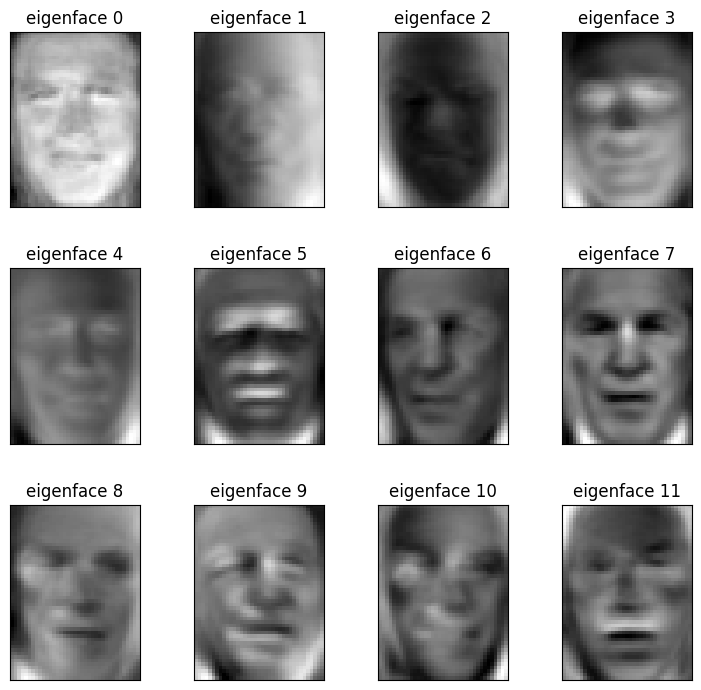

Fitting the classifier to the training set
Done in 0.209s
Predicting people's names on the test set
                   precision    recall  f1-score   support

     Ariel Sharon       1.00      0.64      0.78        11
     Colin Powell       0.63      0.96      0.76        47
  Donald Rumsfeld       0.83      0.68      0.75        22
    George W Bush       0.94      0.91      0.92       119
Gerhard Schroeder       0.89      0.89      0.89        19
      Hugo Chavez       1.00      0.46      0.63        13
       Tony Blair       0.95      0.78      0.86        27

         accuracy                           0.85       258
        macro avg       0.89      0.76      0.80       258
     weighted avg       0.88      0.85      0.85       258

Components needed for 90% variance: 85


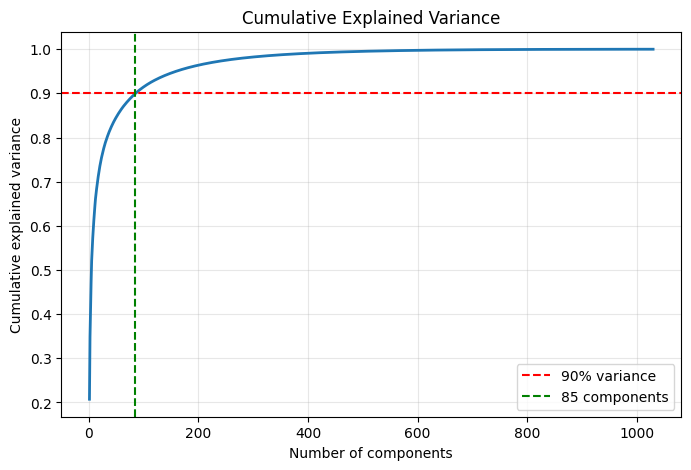

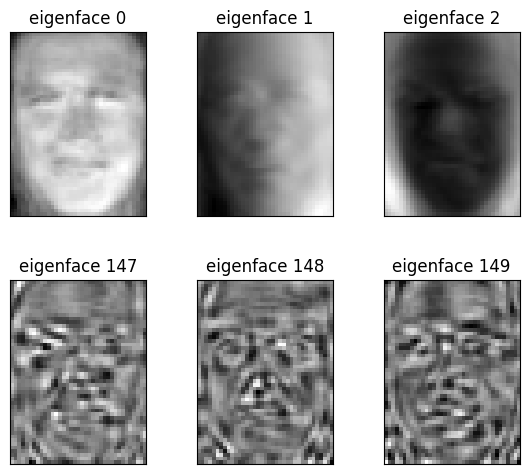

Std of first 5 components (no whitening): [2.91 2.4  1.65 1.52 1.41]
Std of first 5 components (whitened)    : [1. 1. 1. 1. 1.]
Std of last 5 components  (no whitening): [0.14 0.13 0.13 0.13 0.13]
Std of last 5 components  (whitened)    : [1. 1. 1. 1. 1.]
Misclassified: 39 of 258 test images


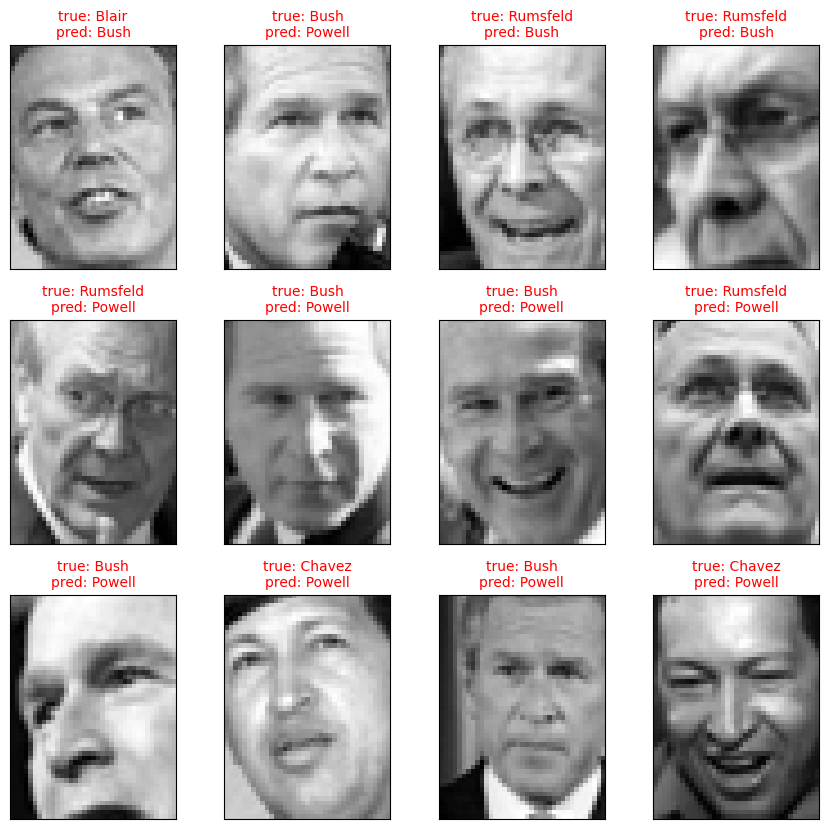

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# ---------------- Task 1: Data Acquisition and Preprocessing ----------------
print("Downloading LFW dataset (this may take a moment)...")
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

n_samples, h, w = lfw_people.images.shape
X = lfw_people.data
y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print("Total dataset size:")
print(f"n_samples: {n_samples}")
print(f"n_features: {X.shape[1]} ({h}x{w} pixels)")
print(f"n_classes: {n_classes}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------- Task 2: Computing the Principal Components ----------------
n_components = 150
print(f"Extracting the top {n_components} eigenfaces from {X_train.shape[0]} faces...")
t0 = time.time()

pca = PCA(n_components=n_components, svd_solver='randomized', whiten=True, random_state=42)
pca.fit(X_train)  # fit on training data only

print(f"Done in {time.time() - t0:.3f}s")

X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

# ---------------- Task 3: Visualizing the Eigenfaces ----------------
eigenfaces = pca.components_.reshape((n_components, h, w))

def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i], cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
    plt.show()

eigenface_titles = [f"eigenface {i}" for i in range(eigenfaces.shape[0])]
plot_gallery(eigenfaces, eigenface_titles, h, w)

# ---------------- Task 4: Face Recognition in the Reduced Space ----------------
print("Fitting the classifier to the training set")
t0 = time.time()

clf = SVC(kernel='rbf', class_weight='balanced')
clf.fit(X_train_pca, y_train)

print(f"Done in {time.time() - t0:.3f}s")

print("Predicting people's names on the test set")
y_pred = clf.predict(X_test_pca)
print(classification_report(y_test, y_pred, target_names=target_names))

# ---------------- Q1: Cumulative Explained Variance ----------------
pca_full = PCA(n_components=None, svd_solver='full')
pca_full.fit(X_train)

cum_var = pca_full.explained_variance_ratio_.cumsum()
n_90 = int(np.argmax(cum_var >= 0.90) + 1)
print(f"Components needed for 90% variance: {n_90}")

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cum_var) + 1), cum_var, linewidth=2)
plt.axhline(0.90, color='red', linestyle='--', label='90% variance')
plt.axvline(n_90, color='green', linestyle='--', label=f'{n_90} components')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ---------------- Q2: First 3 vs last 3 eigenfaces ----------------
imgs = list(eigenfaces[:3]) + list(eigenfaces[-3:])
titles = [f"eigenface {i}" for i in range(3)] + \
         [f"eigenface {i}" for i in range(n_components - 3, n_components)]
plot_gallery(imgs, titles, h, w, n_row=2, n_col=3)

# ---------------- Q3: Effect of whitening ----------------
pca_nw = PCA(n_components=n_components, svd_solver='randomized', whiten=False, random_state=42)
Xtr_nw = pca_nw.fit_transform(X_train)
print("Std of first 5 components (no whitening):", Xtr_nw.std(axis=0)[:5].round(2))
print("Std of first 5 components (whitened)    :", X_train_pca.std(axis=0)[:5].round(2))
print("Std of last 5 components  (no whitening):", Xtr_nw.std(axis=0)[-5:].round(2))
print("Std of last 5 components  (whitened)    :", X_train_pca.std(axis=0)[-5:].round(2))

# ---------------- Q4: Failure analysis ----------------
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong_idx)} of {len(y_test)} test images")

n_show = min(12, len(wrong_idx))
n_col = 4
n_row = int(np.ceil(n_show / n_col))

plt.figure(figsize=(2.2 * n_col, 2.8 * n_row))
for k, i in enumerate(wrong_idx[:n_show]):
    plt.subplot(n_row, n_col, k + 1)
    plt.imshow(X_test[i].reshape(h, w), cmap=plt.cm.gray)
    plt.title(f"true: {target_names[y_test[i]].split()[-1]}\npred: {target_names[y_pred[i]].split()[-1]}",
              size=10, color='red')
    plt.xticks(())
    plt.yticks(())
plt.tight_layout()
plt.show()